# Portada

**UNIVERSIDAD AUTONOMA DEL ESTADO DE MEXICO (UAEMex)**

**Investigación de Operaciones**

**Ingeniería en Computación**

**Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook**

**Práctica: 4. Programacion lineal**

**Integrantes del equipo:**
 - David Alberto Ruiz Gonzalez
 - Alexia Guadalupe Sanchez Zamora

**Fecha:**: 18 noviembre de 2026

# Título del problema

**Asignación óptima de recursos de un clúster de servidores para maximizar la utilidad (Programación Lineal)**

## Descripción y planteamiento

Una empresa de hosting dispone de un clúster con recursos limitados y ofrece dos tipos de máquinas virtuales (VM):

| Tipo de VM | vCPU por VM | RAM (GB) por VM | Almacenamiento (TB) por VM | Utilidad mensual (USD) |
|---|---|---|---|---|
| **Web** ($x_1$) | 2 | 4 | 1 | 50 |
| **Análisis de datos** ($x_2$) | 3 | 2 | 1 | 40 |

**Recursos disponibles del clúster:** 120 vCPU, 160 GB de RAM, 55 TB de almacenamiento. Además, por contrato la demanda máxima de VM de análisis es de **30 unidades**.

**Objetivo:** determinar cuántas VM de cada tipo conviene contratar para **maximizar la utilidad mensual**.

### Formulación matemática

**Variables de decisión**

- $x_1$ = número de VM Web
- $x_2$ = número de VM de Análisis de datos

**Función objetivo**

$$\max\; Z = 50x_1 + 40x_2$$

**Restricciones**

$$\begin{aligned}
2x_1 + 3x_2 &\le 120 && \text{(vCPU)}\\
4x_1 + 2x_2 &\le 160 && \text{(RAM)}\\
x_1 + x_2 &\le 55 && \text{(almacenamiento)}\\
x_2 &\le 30 && \text{(demanda máxima de análisis)}\\
x_1,\,x_2 &\ge 0 && \text{(no negatividad)}
\end{aligned}$$

### Método de solución

1. **Método gráfico:** dibujar la región factible, evaluar $Z$ en sus vértices (el óptimo de un PL siempre está en un vértice).
2. **Solución computacional** con `scipy.optimize.linprog` (solver HiGHS), incluyendo holguras y precios sombra.

## Paso 1. Importación de bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import linprog

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


## Paso 2. Definición de datos

Escribimos el modelo en forma matricial: $\max\, c^T x$ sujeto a $A x \le b$, $x\ge 0$.

In [2]:
c = np.array([50, 40])                       # utilidad por VM
A = np.array([[2, 3],                        # vCPU
              [4, 2],                        # RAM
              [1, 1],                        # almacenamiento
              [0, 1]])                       # demanda máxima de análisis
b = np.array([120, 160, 55, 30])
nombres = ["vCPU", "RAM", "Almacenamiento", "Demanda análisis"]

modelo = pd.DataFrame(A, columns=["x1 (Web)", "x2 (Análisis)"], index=nombres)
modelo["<= disponible"] = b
print("Función objetivo: max Z =", c[0], "x1 +", c[1], "x2")
print()
print(modelo.to_string())

Función objetivo: max Z = 50 x1 + 40 x2

                  x1 (Web)  x2 (Análisis)  <= disponible
vCPU                     2              3            120
RAM                      4              2            160
Almacenamiento           1              1             55
Demanda análisis         0              1             30


## Paso 3. Construcción gráfica de la región factible, restricción por restricción

Partimos del primer cuadrante ($x_1,x_2\ge 0$) y vamos **agregando una restricción a la vez**; la zona sombreada es el conjunto de puntos que cumplen todas las restricciones agregadas hasta ese momento.

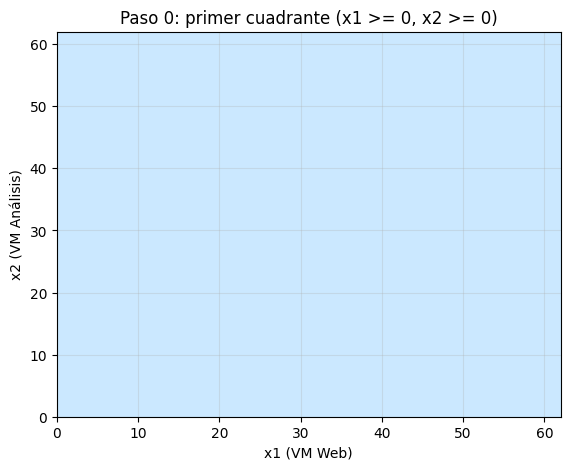

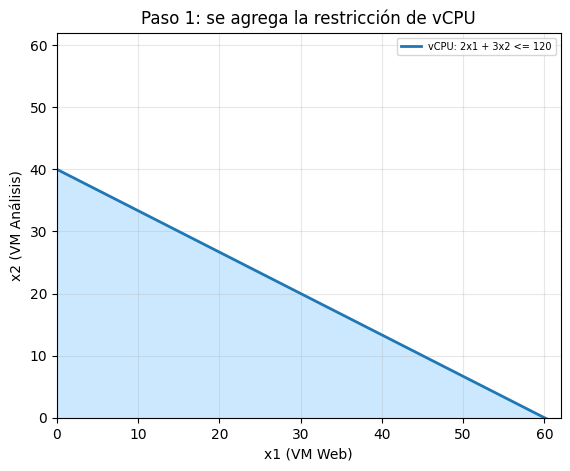

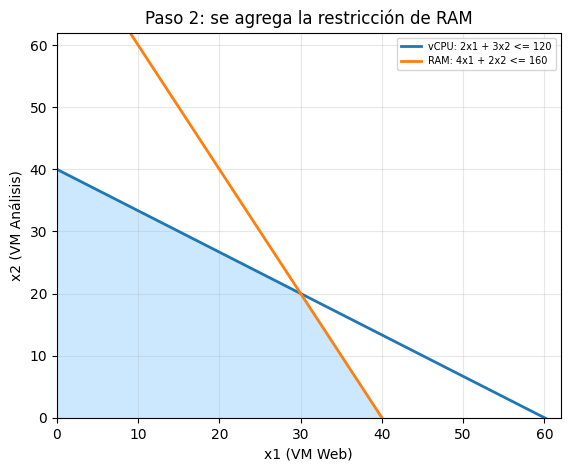

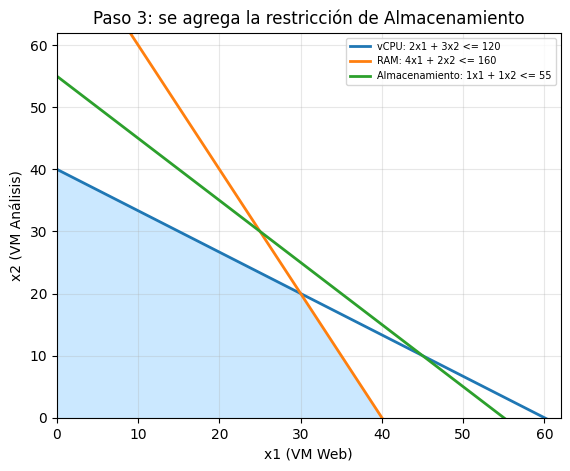

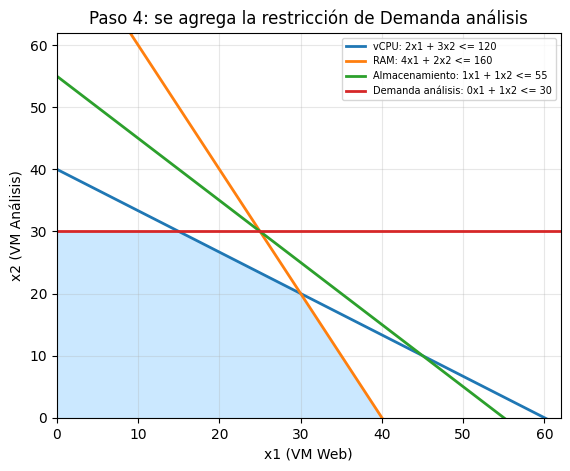

In [3]:
LIM = 62
x1g, x2g = np.meshgrid(np.linspace(0, LIM, 700), np.linspace(0, LIM, 700))
colores = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
xs = np.linspace(0, LIM, 200)


def linea(i):
    # x2 en función de x1 para la restricción i
    return (b[i] - A[i, 0] * xs) / A[i, 1]


def graficar_paso(k, titulo):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    mascara = np.ones_like(x1g, dtype=bool)
    for i in range(k):
        mascara &= (A[i, 0] * x1g + A[i, 1] * x2g <= b[i] + 1e-9)
    ax.contourf(x1g, x2g, mascara.astype(int), levels=[0.5, 1.5], colors=["#bfe3ff"], alpha=0.8)
    for i in range(k):
        ax.plot(xs, linea(i), color=colores[i], lw=2, label=f"{nombres[i]}: {A[i,0]}x1 + {A[i,1]}x2 <= {b[i]}")
    ax.set_xlim(0, LIM)
    ax.set_ylim(0, LIM)
    ax.set_xlabel("x1 (VM Web)")
    ax.set_ylabel("x2 (VM Análisis)")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    if k > 0:
        ax.legend(fontsize=7, loc="upper right")
    plt.show()


graficar_paso(0, "Paso 0: primer cuadrante (x1 >= 0, x2 >= 0)")
for k in range(1, 5):
    graficar_paso(k, f"Paso {k}: se agrega la restricción de {nombres[k-1]}")

## Paso 4. Cálculo de los vértices de la región factible

Los candidatos a óptimo son las intersecciones de pares de rectas (incluyendo los ejes). Conservamos solo las que cumplen **todas** las restricciones y evaluamos $Z$ en cada una.

In [4]:
A_todas = np.vstack([A, [-1, 0], [0, -1]])          # incluye x1>=0 y x2>=0
b_todas = np.concatenate([b, [0, 0]])

vertices = []
for i in range(len(b_todas)):
    for j in range(i + 1, len(b_todas)):
        M = A_todas[[i, j]]
        if abs(np.linalg.det(M)) < 1e-12:
            continue                                  # rectas paralelas
        p = np.linalg.solve(M, b_todas[[i, j]])
        if np.all(A_todas @ p <= b_todas + 1e-9):     # ¿es factible?
            if not any(np.allclose(p, q) for q in vertices):
                vertices.append(p)

vertices = np.array(vertices)
centro = vertices.mean(axis=0)
orden = np.argsort(np.arctan2(vertices[:, 1] - centro[1], vertices[:, 0] - centro[0]))
vertices = vertices[orden]

tabla_v = pd.DataFrame({"x1": vertices[:, 0], "x2": vertices[:, 1], "Z = 50x1 + 40x2": vertices @ c})
print(tabla_v.round(2).to_string(index=False))
mejor = vertices[np.argmax(vertices @ c)]
print("\nMejor vértice:", mejor, "con Z =", mejor @ c)

  x1   x2  Z = 50x1 + 40x2
-0.0 -0.0              0.0
40.0 -0.0           2000.0
30.0 20.0           2300.0
15.0 30.0           1950.0
-0.0 30.0           1200.0

Mejor vértice: [30. 20.] con Z = 2300.0


## Paso 5. Región factible con sus vértices

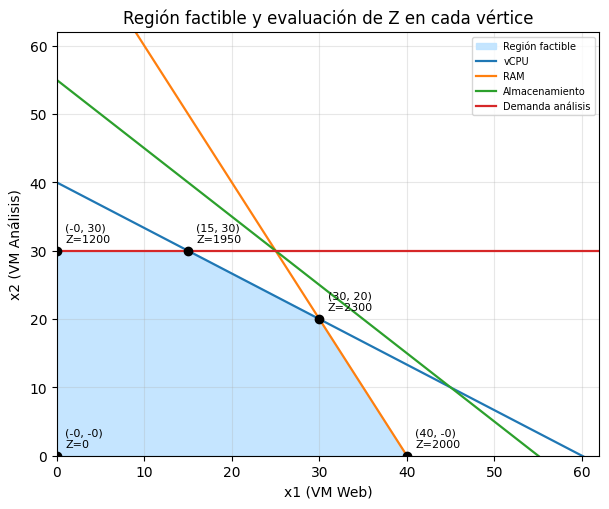

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.fill(vertices[:, 0], vertices[:, 1], color="#bfe3ff", alpha=0.9, label="Región factible")
for i in range(len(b)):
    ax.plot(xs, linea(i), color=colores[i], lw=1.6, label=nombres[i])
ax.scatter(vertices[:, 0], vertices[:, 1], color="black", zorder=5)
for (px, py), z in zip(vertices, vertices @ c):
    ax.annotate(f"({px:.0f}, {py:.0f})\nZ={z:.0f}", (px, py), textcoords="offset points",
                xytext=(6, 6), fontsize=8)
ax.set_xlim(0, 62)
ax.set_ylim(0, 62)
ax.set_xlabel("x1 (VM Web)")
ax.set_ylabel("x2 (VM Análisis)")
ax.set_title("Región factible y evaluación de Z en cada vértice")
ax.legend(fontsize=7, loc="upper right")
ax.grid(alpha=0.3)
plt.show()

## Paso 6. Rectas de nivel de la función objetivo

Cada recta $50x_1+40x_2=Z$ agrupa puntos con la misma utilidad. Al desplazarlas en la dirección del gradiente $(50,40)$, $Z$ crece; el óptimo es el **último punto de la región factible** que toca la recta.

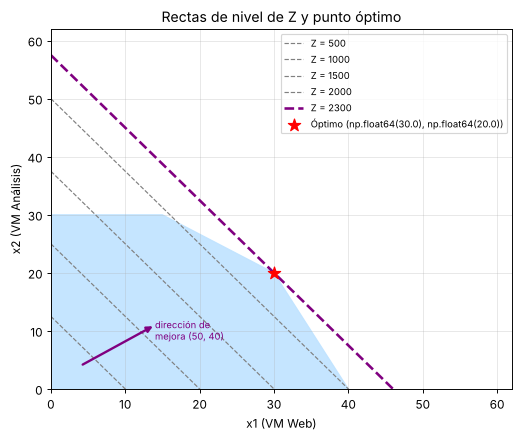

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.fill(vertices[:, 0], vertices[:, 1], color="#bfe3ff", alpha=0.9)
for Z in [500, 1000, 1500, 2000, 2300]:
    ax.plot(xs, (Z - c[0] * xs) / c[1], "--", color="purple" if Z == 2300 else "gray",
            lw=2.2 if Z == 2300 else 1, label=f"Z = {Z}")
ax.annotate("", xy=(14, 11), xytext=(4, 4),
            arrowprops=dict(arrowstyle="-|>", color="purple", lw=2))
ax.text(14, 8.5, "dirección de\nmejora (50, 40)", color="purple", fontsize=8)
ax.scatter(*mejor, color="red", s=120, zorder=5, marker="*", label=f"Óptimo {tuple(mejor.round(0))}")
ax.set_xlim(0, 62)
ax.set_ylim(0, 62)
ax.set_xlabel("x1 (VM Web)")
ax.set_ylabel("x2 (VM Análisis)")
ax.set_title("Rectas de nivel de Z y punto óptimo")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

## Paso 7. Solución con Python (`scipy.optimize.linprog`)

`linprog` **minimiza**, así que maximizamos $Z$ minimizando $-Z$. Usamos el solver HiGHS.

In [6]:
res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)], method="highs")

print("Estado:", res.message)
print(f"x1 (VM Web)      = {res.x[0]:.2f}")
print(f"x2 (VM Análisis) = {res.x[1]:.2f}")
print(f"Utilidad máxima Z = {-res.fun:.2f} USD/mes")
print("¿Coincide con el método gráfico?:", np.allclose(res.x, mejor) and np.isclose(-res.fun, mejor @ c))

Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
x1 (VM Web)      = 30.00
x2 (VM Análisis) = 20.00
Utilidad máxima Z = 2300.00 USD/mes
¿Coincide con el método gráfico?: True


## Paso 8. Uso de recursos, holguras y precios sombra

- **Holgura:** recurso sobrante en el óptimo (0 = restricción activa/limitante).
- **Precio sombra:** cuánto aumentaría $Z$ por cada unidad adicional del recurso.

In [7]:
uso = A @ res.x
sombra = -res.ineqlin.marginals
analisis = pd.DataFrame({
    "Disponible": b,
    "Usado": uso,
    "Holgura": res.slack,
    "Precio sombra (USD/unidad)": sombra,
    "Estado": ["ACTIVA (limitante)" if s < 1e-7 else "con holgura" for s in res.slack],
}, index=nombres)
print(analisis.round(2).to_string())

                  Disponible  Usado  Holgura  Precio sombra (USD/unidad)              Estado
vCPU                     120  120.0      0.0                        7.50  ACTIVA (limitante)
RAM                      160  160.0      0.0                        8.75  ACTIVA (limitante)
Almacenamiento            55   50.0      5.0                        0.00         con holgura
Demanda análisis          30   20.0     10.0                        0.00         con holgura


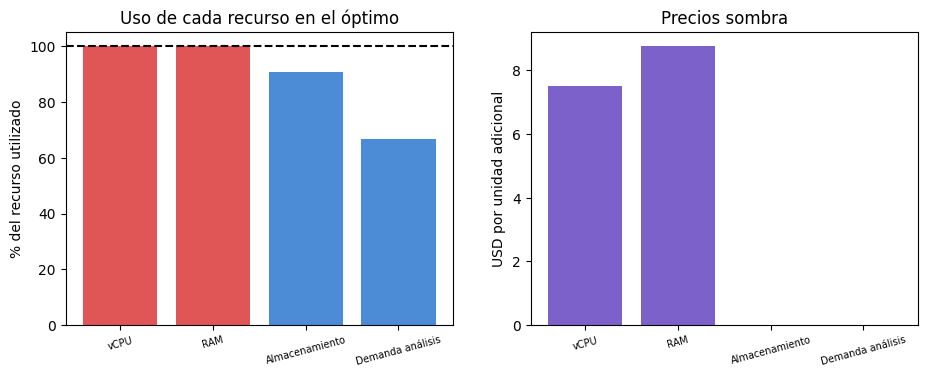

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].bar(nombres, uso / b * 100, color=["#e05555" if s < 1e-7 else "#4c8bd6" for s in res.slack])
axs[0].axhline(100, color="black", ls="--")
axs[0].set_ylabel("% del recurso utilizado")
axs[0].set_title("Uso de cada recurso en el óptimo")
axs[0].tick_params(axis="x", labelsize=7, rotation=15)
axs[1].bar(nombres, sombra, color="#7b61c9")
axs[1].set_ylabel("USD por unidad adicional")
axs[1].set_title("Precios sombra")
axs[1].tick_params(axis="x", labelsize=7, rotation=15)
plt.show()

# Interpretación de resultados

- **Solución óptima:** contratar **30 VM Web** y **20 VM de Análisis de datos**, con una **utilidad máxima de 2,300 USD/mes**.
- Los recursos **limitantes** son **vCPU** y **RAM**: se usan al 100 % (120 de 120 vCPU y 160 de 160 GB). El almacenamiento (50 de 55 TB, 5 TB de holgura) y la demanda de análisis (20 de 30, 10 de holgura) **no** limitan la solución.
- **Precios sombra:** cada vCPU adicional aumentaría la utilidad en **7.50 USD** y cada GB de RAM adicional en **8.75 USD**; los recursos con holgura tienen precio sombra 0, así que ampliarlos no sirve de nada. Si la empresa va a invertir, debe ampliar RAM primero.
- La solución es entera, por lo que es implementable tal cual (no se requiere programación entera).
- El método gráfico y `linprog` coinciden, lo que valida el modelo y el resultado.

## Aplicación al área de Tecnologías de la Información

- **Planeación de capacidad en la nube y data centers:** asignar CPU, RAM y almacenamiento entre servicios.
- **Asignación de recursos en servidores / contenedores** (Kubernetes, máquinas virtuales) y **balanceo de carga**.
- **Planeación de turnos y proyectos de TI**, selección de proyectos con presupuesto limitado.
- Base de técnicas más avanzadas: programación entera, flujos en redes y aprendizaje automático (optimización).

## Conclusiones del equipo


El modelo de programación lineal permitió decidir cuántas máquinas virtuales de cada tipo asignar para maximizar la utilidad (30 Web y 20 de Análisis, 2,300 USD/mes). Construir la región factible restricción por restricción ayudó a visualizar por qué el óptimo está en un vértice, y el análisis de holguras y precios sombra mostró que vCPU y RAM son los recursos críticos. La solución con SciPy coincidió con el método gráfico.


## Conclusiones individuales

| Integrante | Conclusión individual |
|---|---|
| Conclusion (David Alberto)| En este problema pude ver que podemos aplicar programacion lineal como anteriormente estabamos realizando a mano para problemas de transporte, pero ahora para maxiizar la produccion y el rendimiento de un equipo de nube o data centers, y asi ver que parte del equipo puede causar cuello de botella cuando se quiera mejorar o simplemente saber si estamos opteniendo la mayor ganacia posible |
| Conclusion (Alexia Guadalupe) |Con esta práctica aprendí cómo utilizar la programación lineal para aprovechar mejor los recursos disponibles y obtener la mayor utilidad posible. También comprendí la importancia de las restricciones y cómo Python nos ayuda a encontrar una solución óptima. Finalmente, pude relacionar este método con situaciones reales, como la administración de servidores y máquinas virtuales. |
